<div style="background: linear-gradient(120deg, #071E3D 0%, #173B67 58%, #426B91 100%); padding: 28px 36px; border-radius: 14px; display: flex; align-items: center; gap: 28px; box-shadow: 0 4px 18px rgba(0,0,0,0.18);">
    <img src="Figures/iteso.jpg" style="height: 110px; border-radius: 8px; background: white; padding: 6px; flex-shrink: 0;"/>
    <div style="border-left: 2px solid rgba(255,255,255,0.5); padding-left: 28px; color: white;">
        <h1 style="margin: 0 0 8px 0; font-size: 1.5em; line-height: 1.3;">Proyecto Final</h1>
        <h3 style="margin: 0; font-weight: normal; font-size: 1.05em;">Laboratorio de Procesamiento de Datos</h3>
    </div>
</div>

# Guía e instrucciones

En este proyecto, cada equipo resolverá una pregunta relacionada con sus datos mediante un proceso reproducible de extracción, comprensión, limpieza, transformación y análisis. El trabajo debe integrar las herramientas estudiadas en los **Módulos I, II y III**, seleccionar las técnicas pertinentes y explicar por qué se eligieron.

El conjunto de datos y su liga se asignarán a cada equipo. 

**Importante:** no se espera aplicar mecánicamente todos los métodos a cualquier conjunto de datos. El equipo debe justificar la pertinencia de cada transformación. 

## Ficha del equipo y del conjunto de datos

Completa esta ficha antes de comenzar y actualízala si cambia la fuente o el alcance.

| Campo | Información del equipo |
|---|---|
| Número o nombre del equipo | `Equipo 4` |
| Nombre completo de integrante 1 | `Oscar Eduardo de la Fuente Chávez` |
| Nombre completo de integrante 2 | `Maria Rosario Duran Chávez` |
| Nombre completo de integrante 3 | `Diego ` |
| Integrante responsable de coordinación | `Maria Rosario` |
| **Liga del dataset asignado al equipo** |[Dataset](https://iteso01-my.sharepoint.com/:f:/r/personal/gdesirena_iteso_mx/_layouts/15/onedrive.aspx?id=%2Fpersonal%2Fgdesirena%5Fiteso%5Fmx%2FDocuments%2FITESO%2FIngenier%C3%ADa%20y%20Ciencia%20de%20Datos%2FLaboratorio%5Fde%5FProcesamiento%5Fde%5FDatos%5F02026%2FProyecto%20Final%2Fdata%2FDataProyectosFinales%2Fstatlog%2Bgerman%2Bcredit%2Bdata&share=cgr9K69s%5FvTzT6RrnV8I0LXtEgUCkPRFMfGsr1yi4BcYEuFpAw)|

**Responsabilidades del equipo:** acuerden quién coordinara las asesorías sobre el proyecto, esta persona será la responsable de coordinar al equipo y al quién me estaré dirigiendo para preguntas sobre el proyecto.

# Notas

Luego cambiar la liga del dataset para el actualizado y completar el nombre de Diego

Oscar: Voy a poner todos los imports hasta arriba

In [1]:
import os
import pandas as pd
import numpy as np
from IPython.display import Markdown, display
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

## Etapa 1. Planteamiento del problema y objetivo

Antes de programar, escriban en lenguaje claro:

1. ¿Qué situación o necesidad aborda el proyecto?
2. ¿A quién afecta y por qué importa analizarla?
3. ¿Qué preguntas concretas podrían responder con el dataset?
4. ¿Qué evidencia permitiría responderla?
6. ¿Qué no puede concluirse a partir de estos datos?

Si hay una variable objetivo, documenten su definición, unidad de análisis, clases y horizonte temporal. Verifiquen que las variables predictoras estén disponibles en el momento en que se pretende realizar una predicción. Si el proyecto es descriptivo y no tiene objetivo, no inventen uno para poder aplicar WOE o LDA.

## Etapa 2. Fuente y extracción de datos: 

Elijan el método de lectura de acuerdo con el formato disponible, por ejemplo CSV, Excel, JSON, XML, texto, Parquet, HTML o datos geográficos e imágenes cuando sean pertinentes. No conviertan archivos a otro formato sin explicar el motivo. Guarden los datos originales sin sobrescribirlos y registren los pasos de extracción.

En el notebook incluyan el nombre del archivo, la ruta relativa utilizada y una inspección inicial: dimensiones, columnas, tipos, primeras filas y muestra de valores. Eviten rutas absolutas personales para que otras personas del curso puedan reproducir el trabajo.

#### 1. ¿Qué situación o necesidad aborda el proyecto?

Muchos pacientes diabéticos hospitalizados no reciben el manejo preventivo y terapéutico que la evidencia respalda, en parte porque el control de la glucosa en el hospital es poco sistemático. Cuando el manejo falla, el paciente puede volver a ingresar poco después del alta. El proyecto busca identificar, a partir de lo ocurrido durante la hospitalización, qué pacientes tienen más riesgo de ser readmitidos en menos de 30 días.

#### 2. ¿A quién afecta y por qué importa?
Pacientes: Una readmisión temprana suele indicar complicaciones, y afecta su morbilidad y mortalidad.

Hospitales y sistemas de salud: Las readmisiones aumentan los costos y suelen usarse como indicador de calidad de la atención.

Personal clínico: Saber qué perfiles tienen más riesgo permite enfocar el seguimiento posterior al alta (citas, educación, ajuste de tratamiento).

#### 3. Preguntas concretas que se podrían responder
¿Qué proporción de los ingresados termina en readmisión a menos de 30 días?
¿Cambia ese porcentaje según edad, tipo de admisión, especialidad del médico o tiempo de estancia?
¿Que variables se asocian con menos readmisiones?
¿Influyen las visitas previas (ambulatorias, de urgencias, hospitalizaciones) en el riesgo?
¿Qué tan bien se puede predecir la readmisión temprana con la información disponible al momento del alta?

#### 4. ¿Qué evidencia permitiría responderlas?
Descriptiva: Tasas de readmisión por grupo, con tablas y gráficos.
Asociativa: Pruebas de independencia (chi-cuadrado) y comparaciones de distribuciones entre readmitidos y no readmitidos.
Predictiva: Un modelo evaluado en datos no vistos, con métricas apropiadas para clases desbalanceadas (AUC, recall, precisión, no solo exactitud), porque la readmisión < a 30 días es minoritaria.

#### 5. ¿Qué no puede concluirse con estos datos?
Causalidad. Es un estudio observacional. Que el HbA1c medido se asocie con menos readmisiones no prueba que medirlo las cause: los pacientes más graves reciben tratamientos distintos.

Readmisiones en otros hospitales. Solo se ve lo que ocurre dentro de estos sistemas. Un paciente reingresado en otro hospital aparece como "no readmitido".

Vigencia actual. Los datos son de 1999-2008; la práctica clínica, los fármacos y los registros han cambiado.

Todos los pacientes diabéticos. Solo incluye ingresos de 1 a 14 días, con pruebas de laboratorio y medicación. Quedan fuera urgencias sin ingreso, estancias largas y pacientes sin laboratorios.

Equidad entre grupos. Las variables de edad, género y raza son sensibles. Los patrones observados no deben usarse para decidir sobre personas, y la raza puede reflejar desigualdades de acceso, no biología.

In [2]:

dir_base=os.getcwd()
ruta = os.path.join(dir_base, 'diabetic_data.json')
ruta

'C:\\Users\\maria\\proyecto\\diabetic_data.json'

In [3]:

df = pd.read_json(ruta)
print(df.head())
df.shape
print(df.columns)

   encounter_id  patient_nbr             race  gender      age weight  \
0       2278392      8222157             None    None   [0-10)      ?   
1        149190     55629189        Caucasian  Female  [10-20)      ?   
2         64410     86047875  AfricanAmerican  Female  [20-30)      ?   
3        500364     82442376        Caucasian    Male  [30-40)      ?   
4         16680     42519267        Caucasian    Male  [40-50)      ?   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                6.0                      25.0                  1.0   
1                1.0                       1.0                  7.0   
2                1.0                       1.0                  7.0   
3                1.0                       1.0                  7.0   
4                1.0                       1.0                  7.0   

   time_in_hospital  ... citoglipton insulin  glyburide-metformin  \
0               1.0  ...          No      No                   No

In [4]:
#Reemplazar ? con NaN
df = df.replace("?", np.nan)
df.isna().sum()

encounter_id                    0
patient_nbr                     0
race                         7260
gender                       5105
age                          4975
weight                      98735
admission_type_id            5142
discharge_disposition_id     5027
admission_source_id          5004
time_in_hospital             5113
payer_code                  43277
medical_specialty           52477
num_lab_procedures           5146
num_procedures               4955
num_medications              4992
number_outpatient            5139
number_emergency             5153
number_inpatient             5161
diag_1                       5104
diag_2                       5474
diag_3                       6404
number_diagnoses             5163
max_glu_serum                5005
A1Cresult                    5208
metformin                    5072
repaglinide                  5137
nateglinide                  4951
chlorpropamide               5197
glimepiride                  5063
acetohexamide 

In [5]:
#Tipos de columnas
print(df.dtypes)
df.nunique().sort_values()

encounter_id                  int64
patient_nbr                   int64
race                         object
gender                       object
age                          object
weight                       object
admission_type_id           float64
discharge_disposition_id    float64
admission_source_id         float64
time_in_hospital            float64
payer_code                   object
medical_specialty            object
num_lab_procedures          float64
num_procedures              float64
num_medications             float64
number_outpatient           float64
number_emergency            float64
number_inpatient            float64
diag_1                       object
diag_2                       object
diag_3                       object
number_diagnoses            float64
max_glu_serum                object
A1Cresult                    object
metformin                    object
repaglinide                  object
nateglinide                  object
chlorpropamide              

examide                          1
citoglipton                      1
troglitazone                     2
acetohexamide                    2
tolbutamide                      2
glipizide-metformin              2
diabetesMed                      2
metformin-rosiglitazone          2
change                           2
glimepiride-pioglitazone         2
metformin-pioglitazone           2
readmitted                       3
gender                           3
tolazamide                       3
chlorpropamide                   4
glimepiride                      4
glipizide                        4
glyburide                        4
glyburide-metformin              4
acarbose                         4
miglitol                         4
nateglinide                      4
insulin                          4
pioglitazone                     4
rosiglitazone                    4
metformin                        4
A1Cresult                        4
max_glu_serum                    4
repaglinide         

In [6]:
df["diag_1"].value_counts()

diag_1
428    6497
414    6250
786    3826
410    3434
486    3338
       ... 
939       1
477       1
988       1
145       1
V51       1
Name: count, Length: 715, dtype: int64

### Inspección inicial:
##### -Dimensiones:
101766 filas, 50 columnas

##### -Columnas: 
'encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

## Etapa 3. Comprensión y calidad de datos:

Preparen un diccionario de datos que incluya nombre de variable, descripción, tipo, unidad o categorías y papel dentro del análisis. Diferencien tipos físicos (entero, decimal, texto, fecha) de tipos conceptuales (continua, discreta, nominal, ordinal, identificador y objetivo).

Revisen, cuantifiquen y documenten:

- Registros y columnas, filas duplicadas y claves.
- Valores faltantes por variable y posibles patrones de ausencia.
- Valores fuera de rango, inconsistencias, unidades y formatos.
- Distribuciones, categorías raras, desequilibrio de clases y posibles valores atípicos.
- Variables que podrían filtrar información futura o identificar directamente a una persona.

Cada corrección debe tener una razón trazable. Conserven una copia de los datos originales y describan cuántas filas o valores cambian en cada paso. 

Si hay predicción, separen entrenamiento y prueba antes de aprender imputaciones, límites, categorías, bins o codificaciones que dependen de la muestra. 

In [7]:
def clasificar(serie, umbral_discreta=20):
    #si una variable entera tiene 20 valores distintos o menos, es discreta.
    n = serie.nunique()
    prop = n / len(serie)

    if pd.api.types.is_numeric_dtype(serie):
        # 1. Identificador: casi cada fila tiene un valor distinto
        if prop > 0.95:
            return "identificador"
        # 2. Entero (o decimal que en realidad son enteros) -> conteo
        es_entero = (serie.dropna() % 1 == 0).all()
        if es_entero:
            return "discreta"
        # 3. Tiene decimales -> medición
        return "continua"

    return "categórica (nominal u ordinal: revisar)"

In [8]:
tipos = {col: clasificar(df[col]) for col in df.columns}

tabla = pd.DataFrame.from_dict(tipos, orient="index", columns=["tipo_conceptual"])
tabla["Valores unicos"]=df.nunique()
tabla.loc["patient_nbr", "tipo_conceptual"] = "identificador"
tabla.loc["race", "tipo_conceptual"] = "categórica nominal"
#identifica al paciente y se repite entre ingresos, por eso la regla automática no lo detectó.
#Es el número que identifica a cada paciente, no describe ninguna característica suya
#tabla

In [9]:
identificadores = ["encounter_id", "patient_nbr"]
objetivo = ["readmitted"]

ordinales = ["age", "weight", "max_glu_serum", "A1Cresult"]

discretas = ["time_in_hospital", "num_lab_procedures", "num_procedures",
             "num_medications", "number_outpatient", "number_emergency",
             "number_inpatient", "number_diagnoses"]

medicamentos = ["metformin", "repaglinide", "nateglinide", "chlorpropamide",
                "glimepiride", "acetohexamide", "glipizide", "glyburide",
                "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
                "miglitol", "troglitazone", "tolazamide", "insulin",
                "glyburide-metformin", "glipizide-metformin",
                "glimepiride-pioglitazone", "metformin-rosiglitazone",
                "metformin-pioglitazone"]

constantes = ["examide", "citoglipton"]   # un solo valor: se excluyen

nominales = (["race", "gender", "payer_code", "medical_specialty",
              "diag_1", "diag_2", "diag_3",
              "admission_type_id", "admission_source_id", "discharge_disposition_id",
              "change", "diabetesMed"]
             + medicamentos)

In [10]:
enteras = ["admission_type_id", "discharge_disposition_id", "admission_source_id",
           "time_in_hospital", "num_lab_procedures", "num_procedures",
           "num_medications", "number_outpatient", "number_emergency",
           "number_inpatient", "number_diagnoses"]
df[enteras] = df[enteras].astype("Int64")

In [11]:
tabla.loc[identificadores, "tipo_conceptual"] = "identificador"
tabla.loc[objetivo, "tipo_conceptual"] = "objetivo"
tabla.loc[ordinales, "tipo_conceptual"] = "ordinal"
tabla.loc[nominales, "tipo_conceptual"] = "nominal"
tabla.loc[constantes, "tipo_conceptual"] = "constante"
tabla.loc[discretas, "tipo_conceptual"] = "discreta"
#tabla

In [12]:
descripciones = {
    # Identificadores y objetivo
    "encounter_id": "Número único de cada ingreso hospitalario.",
    "patient_nbr": "Número único de cada paciente. Se repite si el paciente tuvo varios ingresos.",
    "readmitted": "Si el paciente volvió al hospital tras el alta: en menos de 30 días (<30), después de 30 días (>30) o nunca (NO).",

    # Demográficas
    "race": "Raza o etnia reportada del paciente.",
    "gender": "Género del paciente.",
    "age": "Grupo de edad del paciente, en intervalos de 10 años.",
    "weight": "Rango de peso del paciente. Casi todos los valores faltan.",

    # Datos administrativos
    "admission_type_id": "Código del tipo de admisión (emergencia, urgente, electiva, etc.).",
    "admission_source_id": "Código del origen del paciente al ingresar (urgencias, derivación médica, otro hospital, etc.).",
    "discharge_disposition_id": "Código del destino del paciente al alta (casa, otro centro, fallecido, cuidados paliativos, etc.).",
    "payer_code": "Código del tipo de seguro o entidad que paga la atención.",
    "medical_specialty": "Especialidad médica del profesional que admitió al paciente.",

    # Estancia
    "time_in_hospital": "Días de hospitalización en este ingreso (de 1 a 14).",
    "num_lab_procedures": "Número de pruebas de laboratorio realizadas durante el ingreso.",
    "num_procedures": "Número de procedimientos (distintos de laboratorio) realizados durante el ingreso.",
    "num_medications": "Número de medicamentos distintos administrados durante el ingreso.",
    "number_diagnoses": "Número de diagnósticos registrados en el ingreso.",

    # Historial del año previo
    "number_outpatient": "Visitas ambulatorias del paciente en el año anterior al ingreso.",
    "number_emergency": "Visitas a urgencias del paciente en el año anterior al ingreso.",
    "number_inpatient": "Hospitalizaciones del paciente en el año anterior al ingreso.",

    # Diagnósticos y pruebas
    "diag_1": "Diagnóstico principal del ingreso, en código CIE-9.",
    "diag_2": "Primer diagnóstico secundario del ingreso, en código CIE-9.",
    "diag_3": "Segundo diagnóstico secundario del ingreso, en código CIE-9.",
    "max_glu_serum": "Resultado de la prueba de glucosa en suero (None = no se midió).",
    "A1Cresult": "Resultado de la prueba de HbA1c, que refleja el control de glucosa de los últimos meses (None = no se midió).",

    # Medicación general
    "change": "Si hubo algún cambio en la medicación de la diabetes durante el ingreso.",
    "diabetesMed": "Si se recetó algún medicamento para la diabetes durante el ingreso.",
}

# Medicamentos: misma descripción para todos
medicamentos_desc = {
    "examide": "sin variación (siempre No)",
    "citoglipton": "sin variación (siempre No)",
}
for med in medicamentos + constantes:
    extra = f" Columna {medicamentos_desc[med]}." if med in medicamentos_desc else ""
    descripciones[med] = (f"Si se administró {med} y cómo cambió la dosis durante el ingreso "
                          f"(No, Down, Steady, Up).{extra}")

tabla["descripcion"] = pd.Series(descripciones)
#tabla

In [13]:
def tipo_fisico(serie):
    if pd.api.types.is_bool_dtype(serie):
        return "booleano"
    if pd.api.types.is_integer_dtype(serie):
        return "entero"
    if pd.api.types.is_float_dtype(serie):
        return "decimal"
    if pd.api.types.is_datetime64_any_dtype(serie):
        return "fecha"
    return "texto"

tabla["tipo_fisico"] = [tipo_fisico(df[c]) for c in tabla.index]
#tabla

In [14]:
# 1. Unidades de las numéricas
unidades = {
    "time_in_hospital": "días",
    "num_lab_procedures": "pruebas (conteo)",
    "num_procedures": "procedimientos (conteo)",
    "num_medications": "medicamentos (conteo)",
    "number_diagnoses": "diagnósticos (conteo)",
    "number_outpatient": "visitas (conteo)",
    "number_emergency": "visitas (conteo)",
    "number_inpatient": "hospitalizaciones (conteo)",
}

# 2. Categorías: la lista si son pocas, o cuántas hay si son muchas
def categorias(serie, max_cat=10):
    vals = serie.dropna().unique()
    if len(vals) <= max_cat:
        texto = []
        for v in vals:
            texto.append(str(v))           # cada valor como texto
        texto.sort()                       # ordenar alfabéticamente
        return ", ".join(texto) # unir con comas
    return f"{len(vals)} categorías"

# 3. Unir todo
def unidad_o_categorias(col):
    if col in identificadores:
        return "Sin unidad"
    if col in unidades:
        return f"{unidades[col]} (rango {df[col].min()} a {df[col].max()})"
    return categorias(df[col])

tabla["unidad_o_categorias"] = [unidad_o_categorias(c) for c in tabla.index]

In [15]:
#Papel dentro del dataset
tabla["papel"] = "predictora"
tabla.loc[identificadores, "papel"] = "identificador"
tabla.loc[objetivo, "papel"] = "objetivo"
tabla.loc[constantes, "papel"] = "excluir (un solo valor)"
tabla.loc["weight", "papel"] = "candidata a excluir (muchos faltantes)"
#tabla

In [16]:
tabla.to_csv("diccionario_datos.csv", index_label="variable", encoding="utf-8-sig")

In [17]:
tabla_md = tabla.reset_index().rename(columns={"index": "variable"})
#display(Markdown(tabla_md.to_markdown(index=False)))

Revisen, cuantifiquen y documenten:

- Registros y columnas, filas duplicadas y claves.
- Valores faltantes por variable y posibles patrones de ausencia.
- Valores fuera de rango, inconsistencias, unidades y formatos.
- Distribuciones, categorías raras, desequilibrio de clases y posibles valores atípicos.
- Variables que podrían filtrar información futura o identificar directamente a una persona.

In [18]:
print(df.shape)                                 
print("Filas duplicadas completas:", df.duplicated().sum())
print("encounter_id repetidos:", df["encounter_id"].duplicated().sum())
print("Pacientes distintos:", df["patient_nbr"].nunique())
print("Pacientes con más de un ingreso:", (df["patient_nbr"].value_counts() > 1).sum())

(101766, 50)
Filas duplicadas completas: 0
encounter_id repetidos: 0
Pacientes distintos: 71518
Pacientes con más de un ingreso: 16773


In [19]:
nulos = pd.DataFrame({
    "n_nulos": df.isnull().sum(),
    "pct_nulos": (df.isnull().mean() * 100).round(2),
})
nulos

,n_nulos,pct_nulos
encounter_id,0,0.00
patient_nbr,0,0.00
race,7260,7.13
gender,5105,5.02
age,4975,4.89
weight,98735,97.02
admission_type_id,5142,5.05
discharge_disposition_id,5027,4.94
admission_source_id,5004,4.92
time_in_hospital,5113,5.02


In [20]:
#patrones de datos faltantes
df["weight"].value_counts()

weight
[75-100)     1269
[50-75)       850
[100-125)     597
[125-150)     133
[25-50)        90
[0-25)         45
[150-175)      35
[175-200)      10
>200            2
Name: count, dtype: int64

Weight tiene un 97% de valores faltantes. La ausencia es compatible con MAR si la tasa varía según errores de medición del hospital; no puede descartarse MNAR (por ejemplo, que se omita con más frecuencia en pacientes de mayor peso), pero no es verificable con estos datos. Dado el porcentaje, la variable se excluye del análisis

<Axes: >

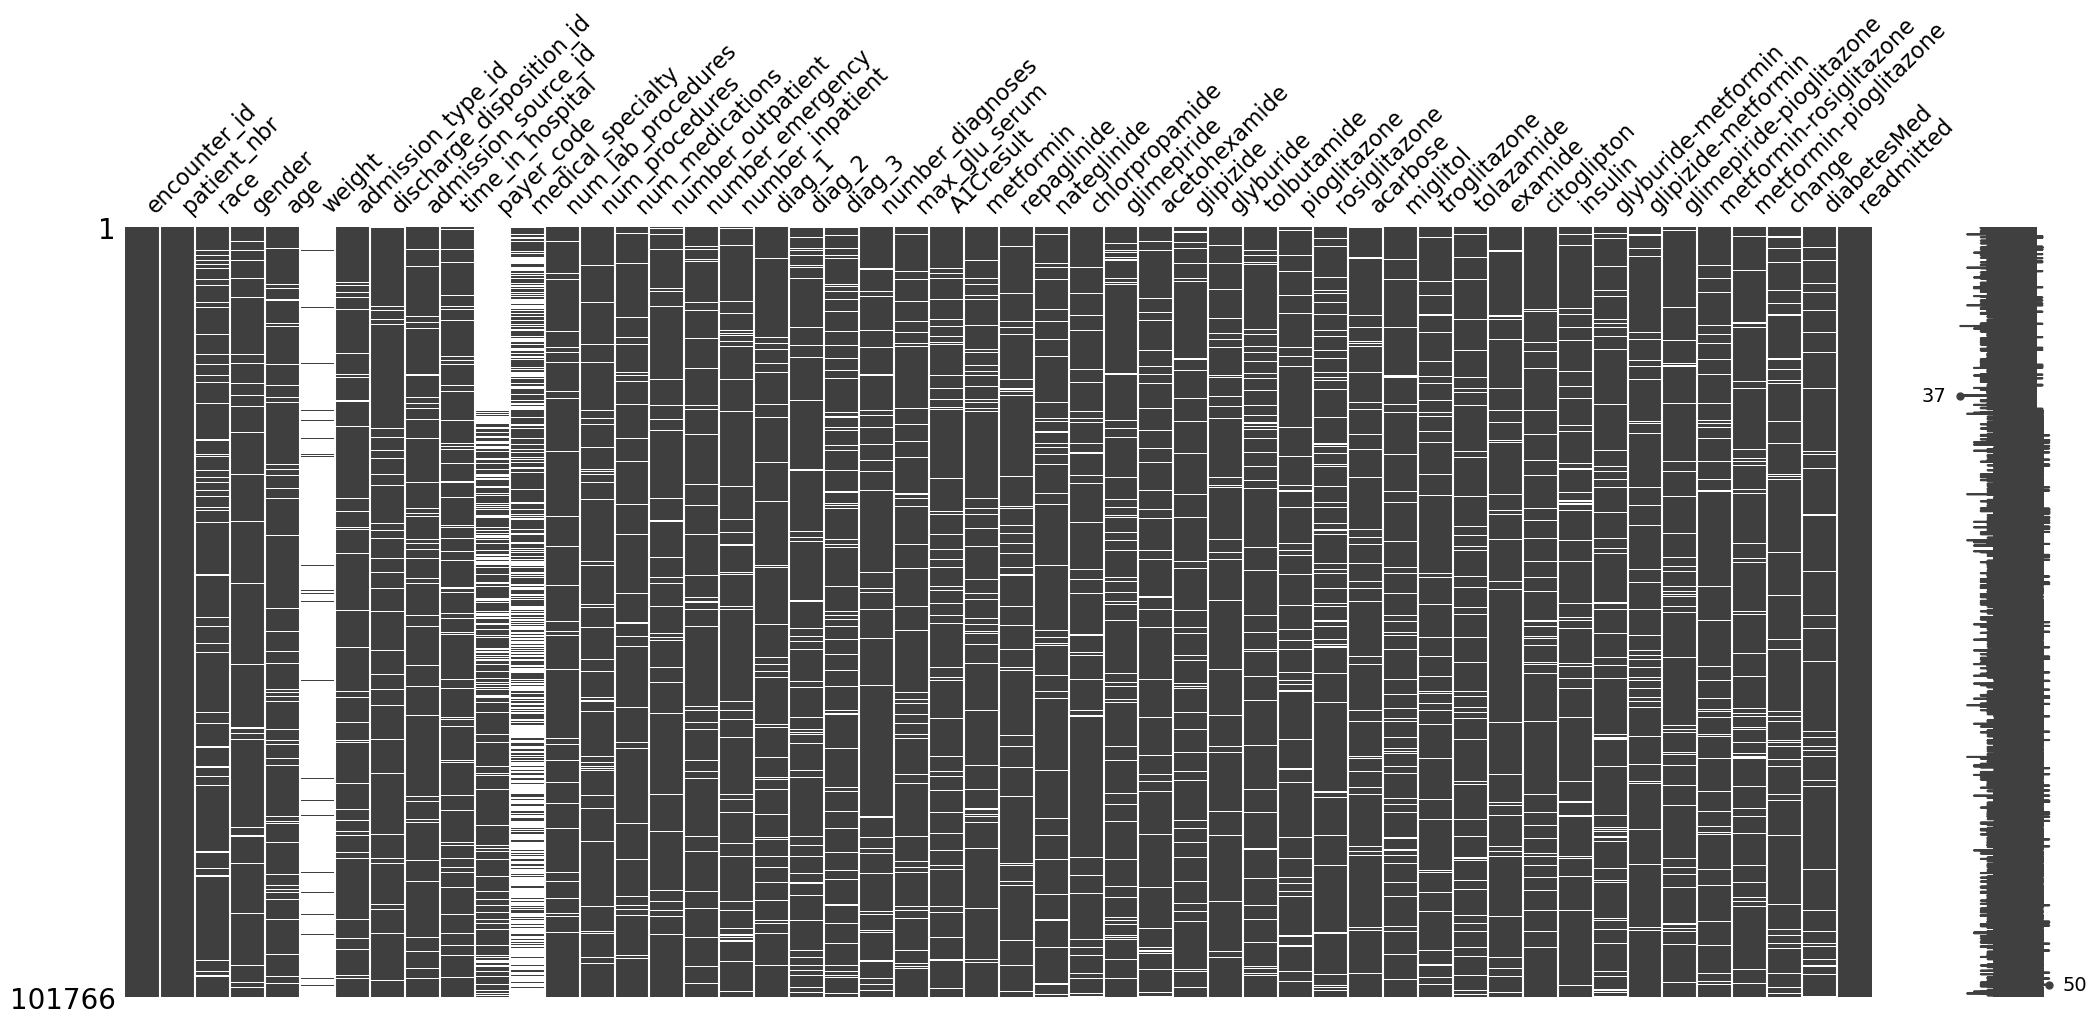

In [21]:
msno.matrix(df)

<Axes: >

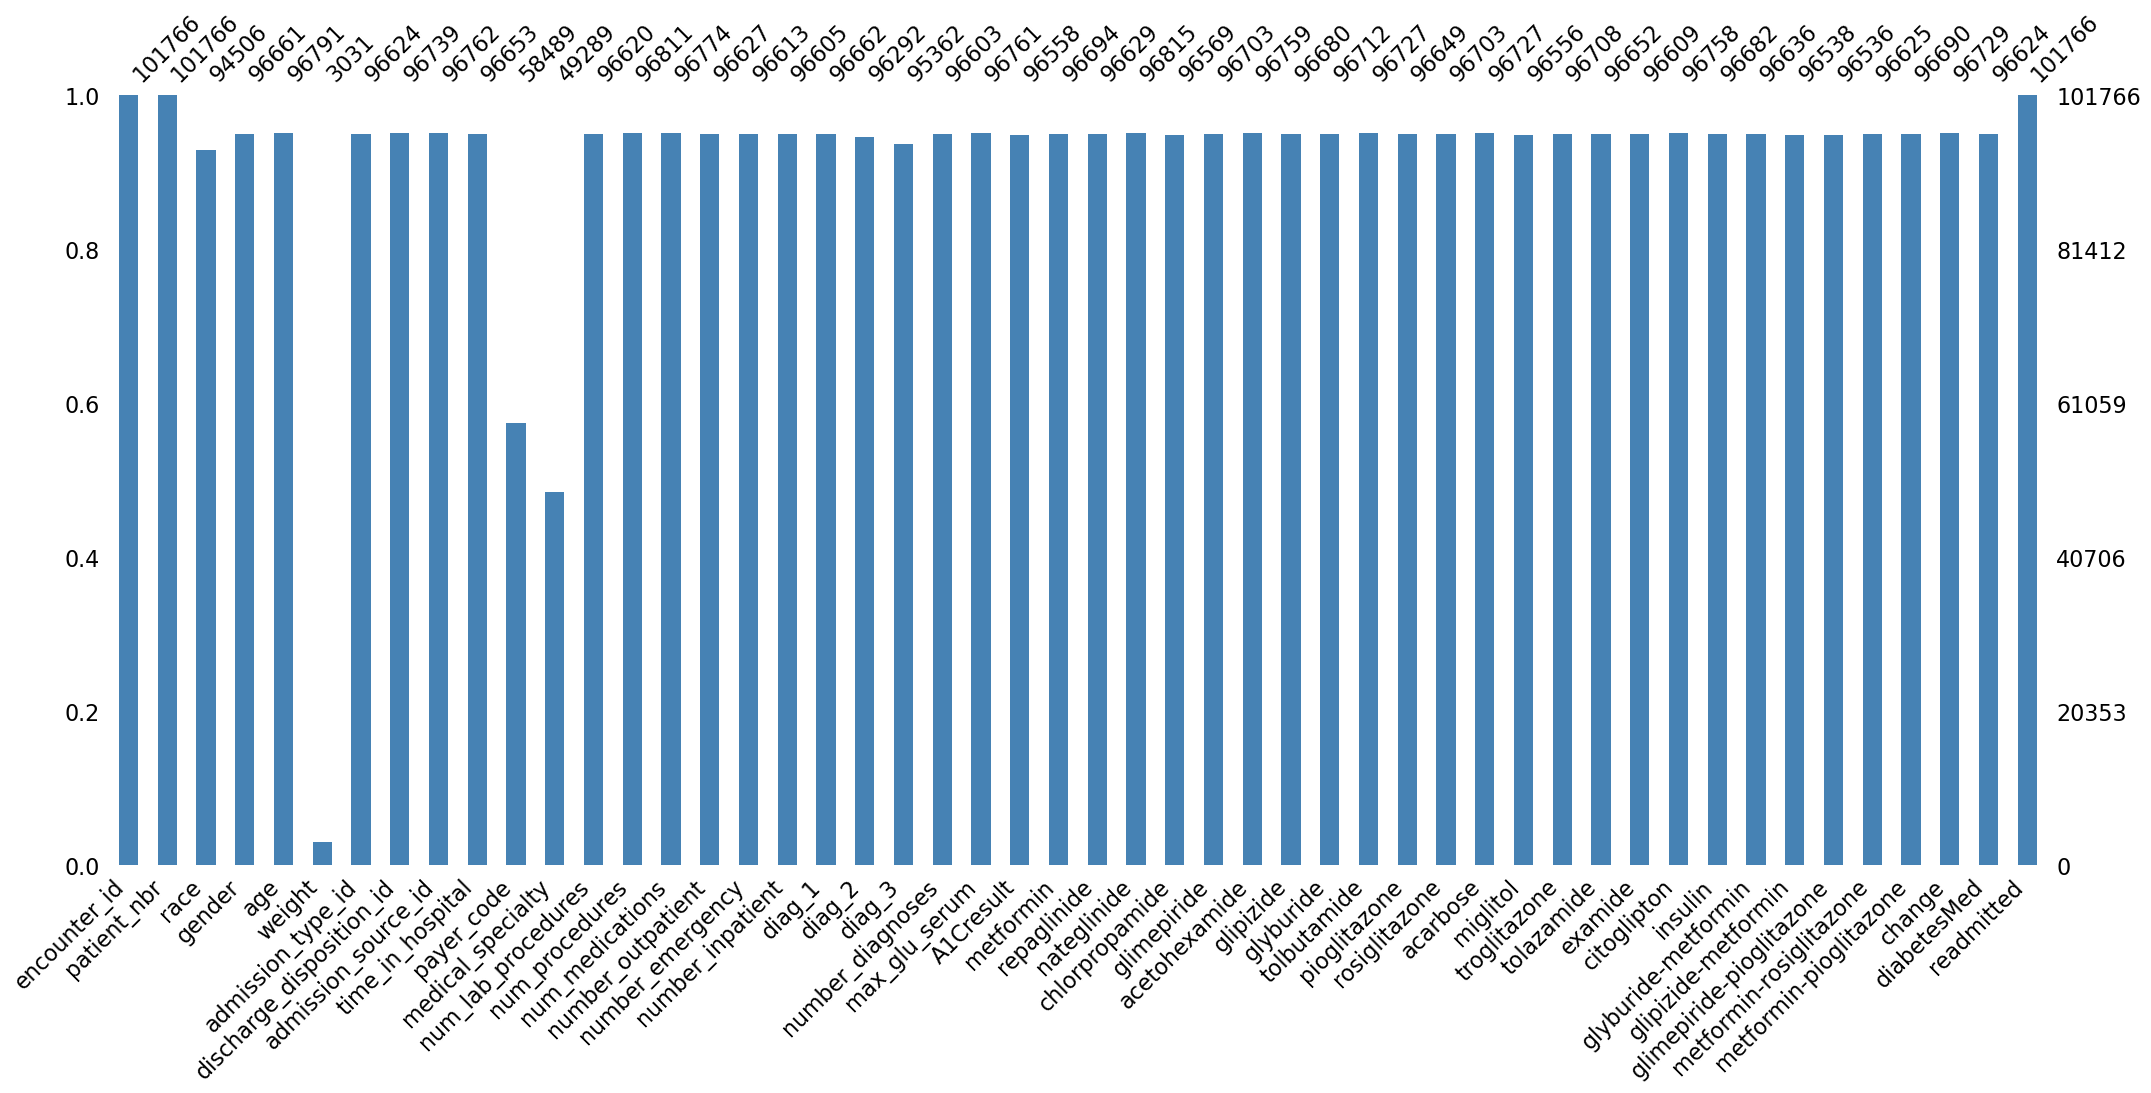

In [22]:
msno.bar(df, color='steelblue')

In [23]:
df['weight_missing'] = df['weight'].isnull()

df.groupby('weight_missing').mean(numeric_only=True)

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
weight_missing,,,,,,,,,,,,,
False,1.556027e+08,7.115778e+07,2.406651,2.690219,6.131524,4.791377,53.015939,1.496877,16.305197,1.079667,0.225244,0.569536,7.966237
True,1.654963e+08,5.381383e+07,2.012119,3.747406,5.738007,4.381447,42.807348,1.335722,16.01297,0.348197,0.197333,0.636778,7.406487


##### Patrones de ausencia PENDIENTE
Al comparar las estadísticas descriptivas de los registros con peso faltante y los registros con peso disponible, no se identificaron diferencias importantes en los promedios de las variables numéricas analizadas. Esto podría sugerir que la ausencia no está relacionada con dichas variables; sin embargo, no es suficiente para confirmar un mecanismo MCAR.

#### Valores fuera de rango

In [24]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,96624.0,96739.0,96762.0,96653.0,96620.0,96811.0,96774.0,96627.0,96613.0,96605.0,96603.0
mean,1.652016e+08,5.433040e+07,2.023907,3.716009,5.749695,4.393645,43.112275,1.340519,16.021628,0.370052,0.198162,0.634781,7.423134
std,1.026403e+08,3.869636e+07,1.445908,5.282917,4.057719,2.983258,19.659565,1.707462,8.120243,1.272625,0.93549,1.261773,1.933658
min,1.252200e+04,1.350000e+02,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
25%,8.496119e+07,2.341322e+07,1.0,1.0,1.0,2.0,31.0,0.0,10.0,0.0,0.0,0.0,6.0
50%,1.523890e+08,4.550514e+07,1.0,1.0,7.0,4.0,44.0,1.0,15.0,0.0,0.0,0.0,8.0
75%,2.302709e+08,8.754595e+07,3.0,4.0,7.0,6.0,57.0,2.0,20.0,0.0,0.0,1.0,9.0
max,4.438672e+08,1.895026e+08,8.0,28.0,25.0,14.0,132.0,6.0,81.0,42.0,76.0,21.0,16.0


Se buscan valores mínimos negativos cuando no deberían existir, máximos exageradamente grandes o valores que no tengan sentido para la variable. No se identificó ninguno. 

 #### Distribuciones, categorías raras, desequilibrio de clases y posibles valores atípicos.

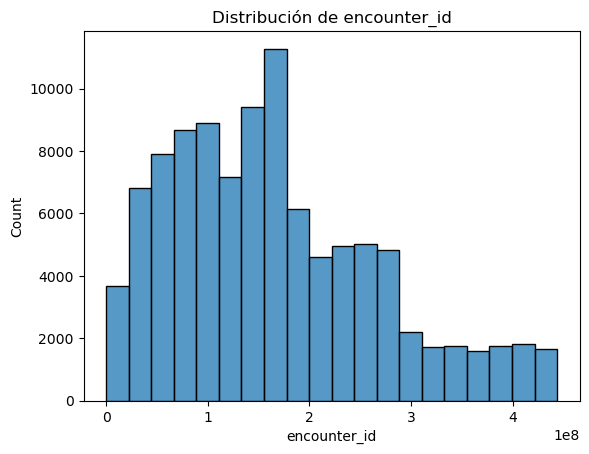

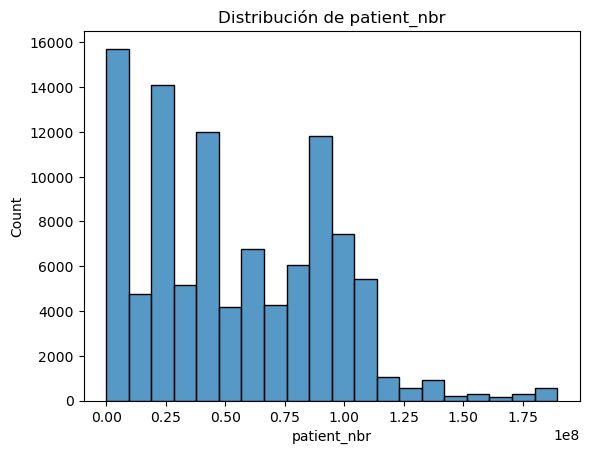

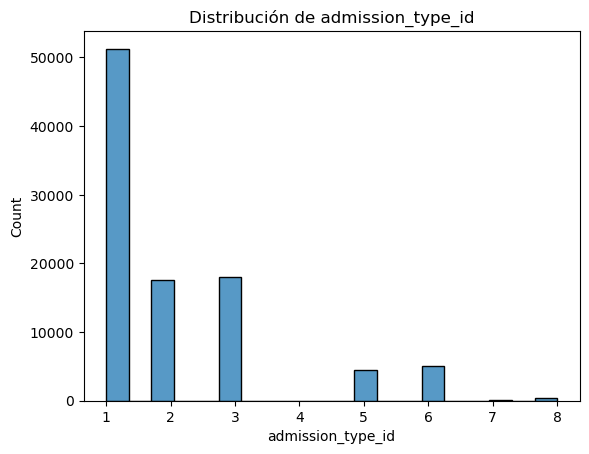

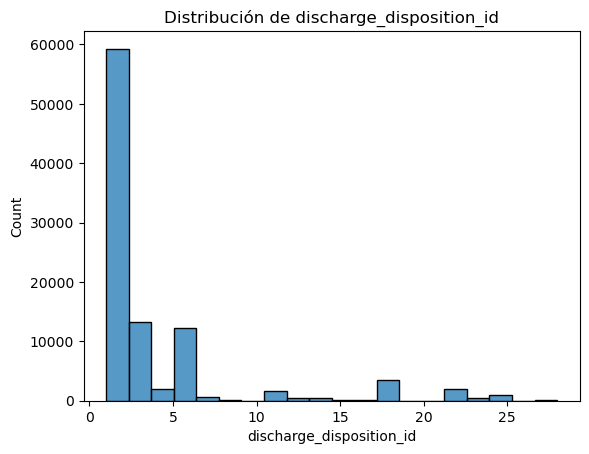

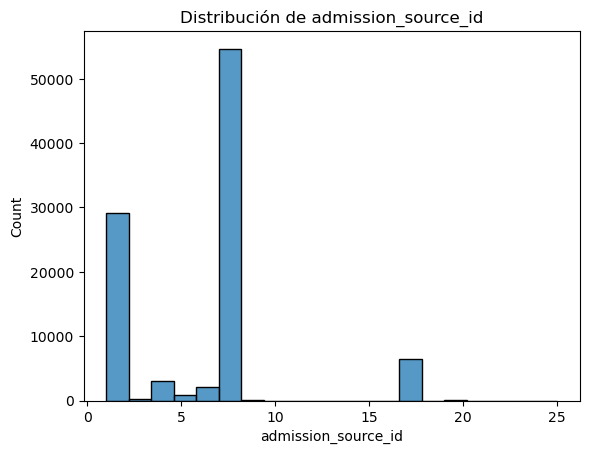

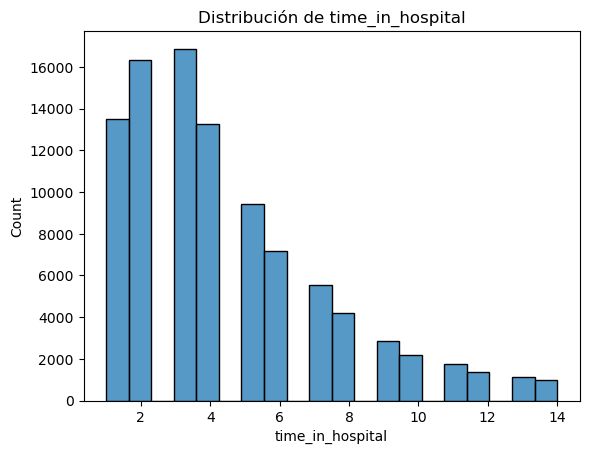

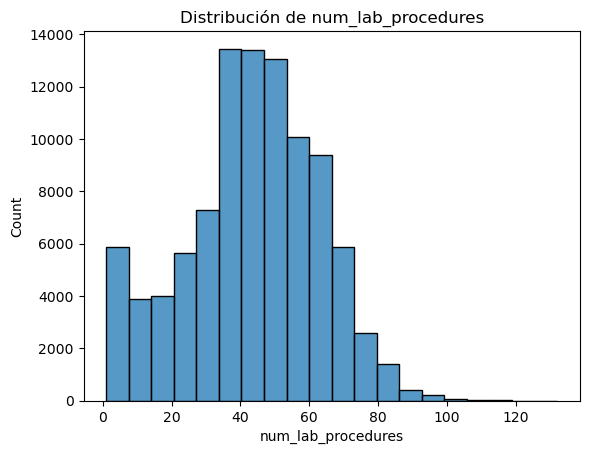

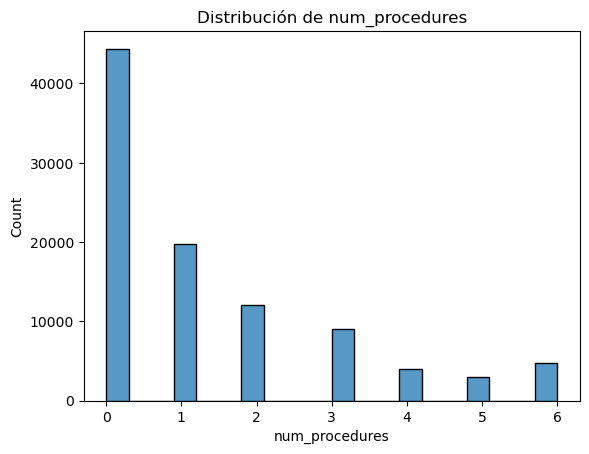

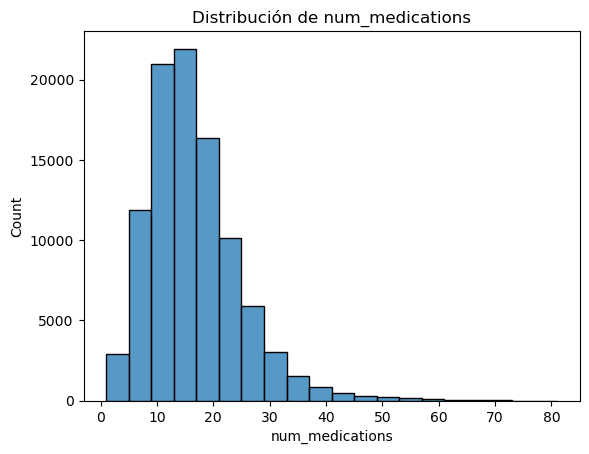

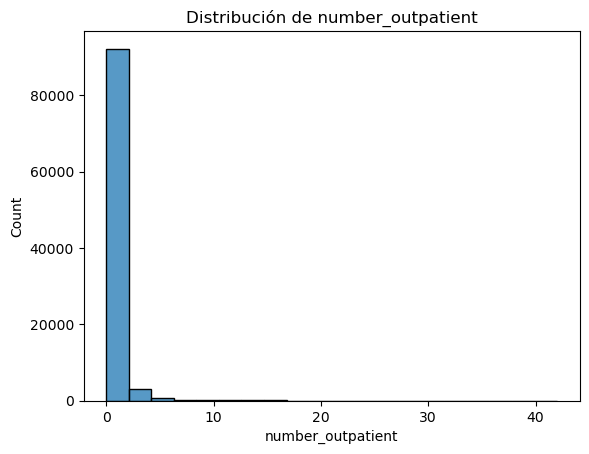

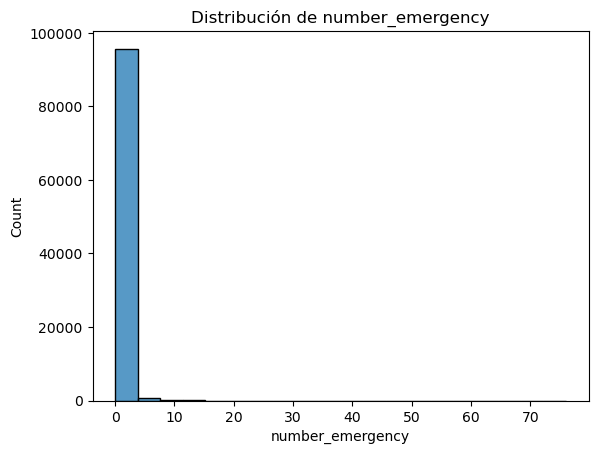

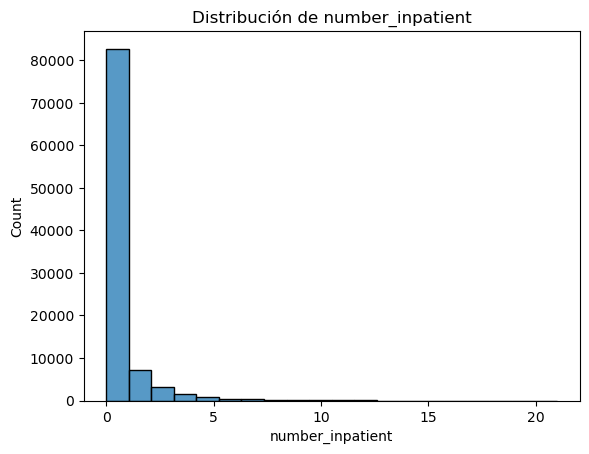

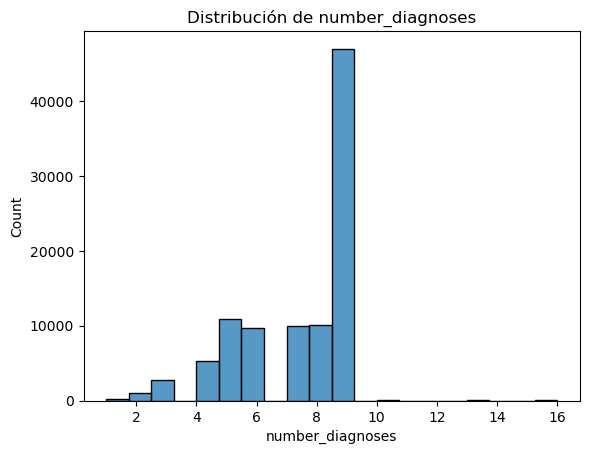

In [25]:
for columna in df.select_dtypes(include='number').columns:
    sns.histplot(data=df, x=columna, bins=20)
    plt.title(f'Distribución de {columna}')
    plt.show()

In [26]:
### 2. Categorías raras
for columna in df.select_dtypes(include='number').columns:
    print(df[columna].value_counts())

encounter_id
2278392      1
190792044    1
190790070    1
190789722    1
190786806    1
            ..
106665324    1
106657776    1
106644876    1
106644474    1
443867222    1
Name: count, Length: 101766, dtype: int64
patient_nbr
88785891     40
43140906     28
1660293      23
88227540     23
23199021     23
             ..
11005362      1
98252496      1
1019673       1
13396320      1
175429310     1
Name: count, Length: 71518, dtype: int64
admission_type_id
1    51286
3    17944
2    17507
6     5035
5     4513
8      308
7       21
4       10
Name: count, dtype: Int64
discharge_disposition_id
1     57300
3     13237
6     12261
18     3517
2      2012
22     1898
11     1558
5      1132
25      943
4       772
7       584
23      388
13      379
14      353
28      133
8       102
15       60
24       44
9        19
17       14
16       10
19        8
10        5
27        5
12        3
20        2
Name: count, dtype: Int64
admission_source_id
7     54675
1     28101
17     6406


No se encontaron categorías raras

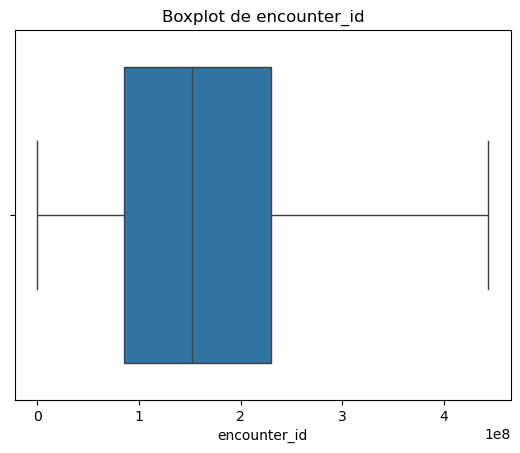

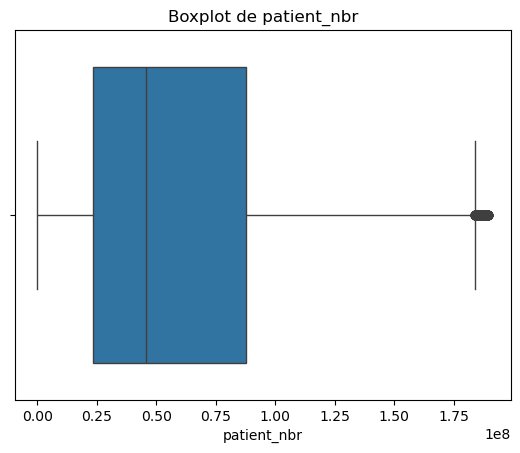

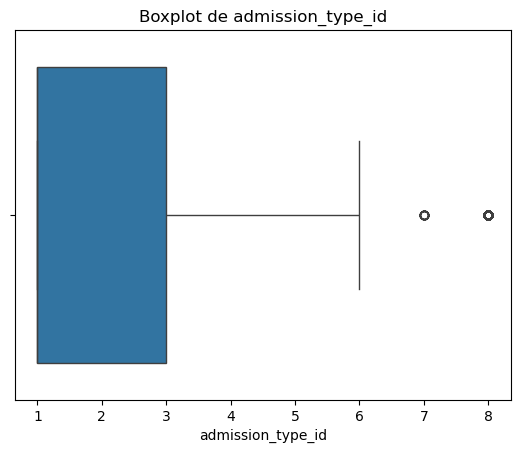

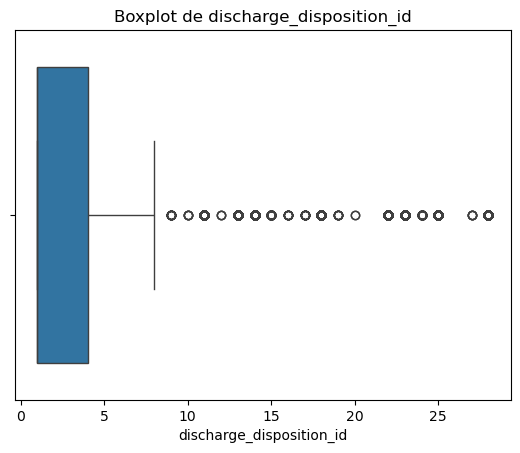

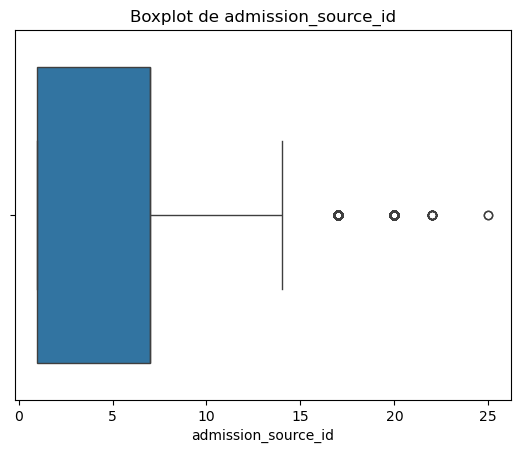

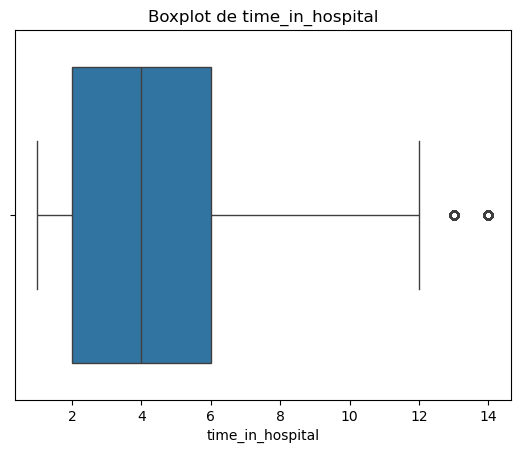

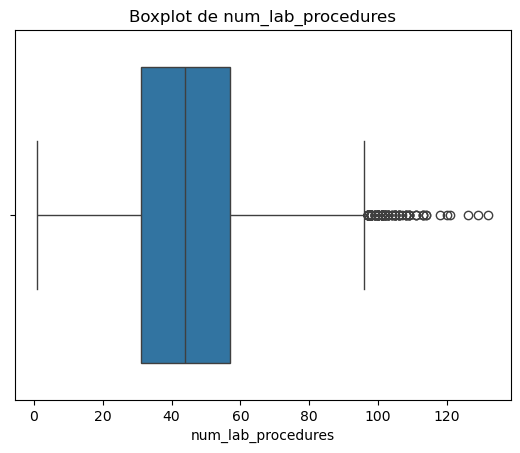

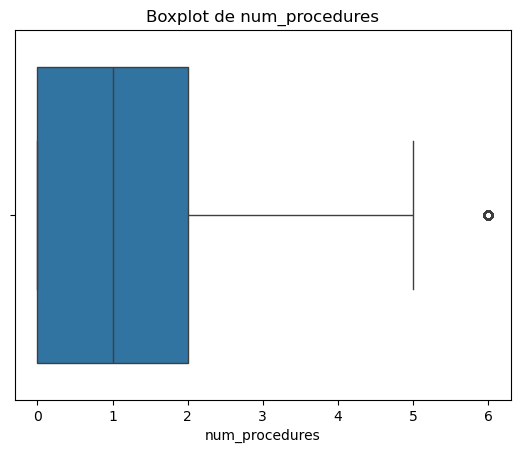

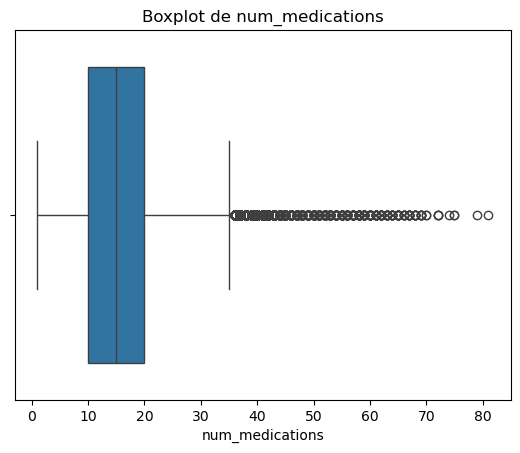

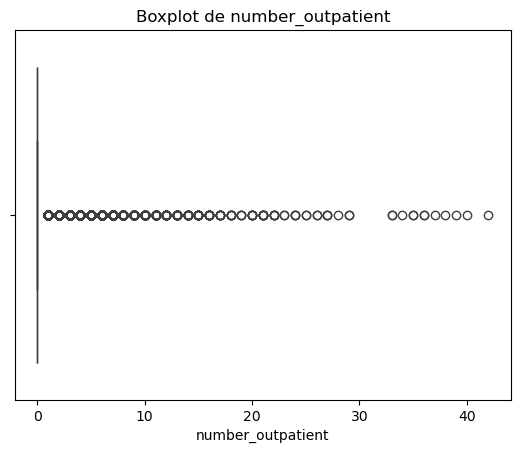

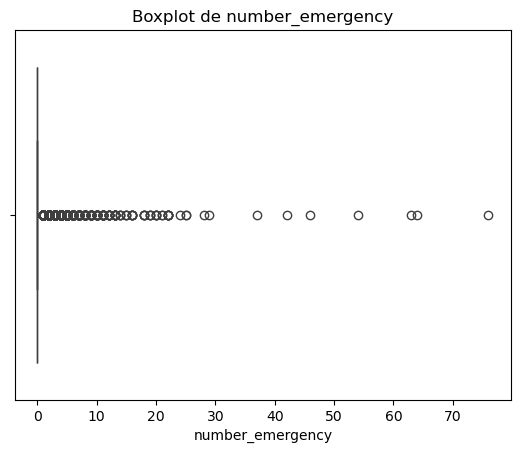

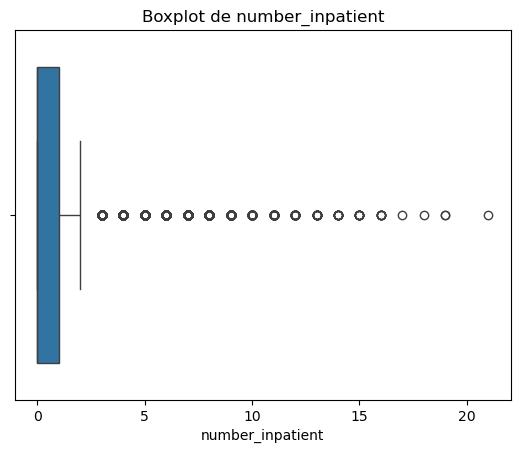

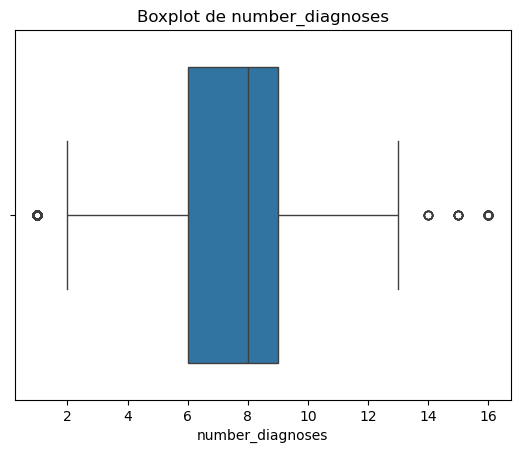

In [27]:
#posibles atípicos
for columna in df.select_dtypes(include='number').columns:
    sns.boxplot(data=df, x=columna)
    plt.title(f'Boxplot de {columna}')
    plt.show()

Los boxplots sugieren la presencia de posibles valores atípicos en algunas variables numéricas. En esta fase únicamente se documentan; su tratamiento y validación se realizará durante la siguiente etapa del análisis.

#### Variables que podrían filtrar información futura o identificar directamente a una persona
Se identificaron variables como "encounter_id" y "patient_nbr". Estas variables no aportan información predictiva y podrían comprometer la privacidad de los registros, por lo que se consideran candidatas para excluirse en etapas posteriores- 

## Etapa 4. Limpieza, transformación y construcción de características: Módulo II

Justifiquen y documenten solo los procedimientos que correspondan a los datos:

- **Faltantes:** decidir si se conserva el registro, se imputa o se crea un indicador, explicar la elección
- **Atípicos y rangos:** distinguir un valor extremo válido de un error. Documentar reglas de detección y cualquier tratamiento, no eliminarlos automáticamente.
- **Escalas:** comparar unidades y distribuciones. Estandarización o normalización se ajustan en entrenamiento y se aplican sin recalcular a prueba.
- **Enriquecimiento:** crear variables derivadas que tengan sentido para la pregunta y explicar la fórmula.
- **Categóricas nominales:** considerar variables dummy/one-hot, no inventar un orden.
- **Categóricas ordinales:** definir y justificar el orden antes de codificar, las distancias numéricas implicadas también requieren justificación.
- **Variables polinomiales:** usarlas para representar curvatura cuando exista una razón.

Registren antes y después: tipos, dimensiones, faltantes y ejemplos de filas. Si no aplican una técnica, indiquen brevemente por qué no es pertinente.

# Faltantes
Todas las columnas a excepcion de identificadores y la variable objetivo presentan datos faltantes. Con porcentajes desde 4.8% hasta 97%. 
Las columnas categóricas se rellenarán con la moda y las numéricas con la mediana porque presentan valores atípicos y distribuciones asimétricas. 


In [28]:
# 1. Crear copia para no sobrescribir el original 
df_imputado = df.copy()

# Columnas a excluir de esta imputación (por alto % de nulos)
excluir = ["weight", "payer_code", "medical_specialty"]

# 2. Variables numéricas discretas -> Mediana
cols_mediana = [c for c in discretas if c not in excluir]
for col in cols_mediana:
    mediana = df_imputado[col].median()
    df_imputado[col] = df_imputado[col].fillna(mediana)

# 3. Variables categóricas (nominales y ordinales) -> Moda
cols_moda = [c for c in (nominales + ordinales) if c not in excluir]
for col in cols_moda:
    moda = df_imputado[col].mode()[0]
    df_imputado[col] = df_imputado[col].fillna(moda)

df_imputado.isna().sum()[df_imputado.isna().sum() > 0]

weight               98735
payer_code           43277
medical_specialty    52477
examide               5157
citoglipton           5008
dtype: int64

In [29]:
#Las columnas weight y payer_code se eliminarán por alto porcentaje de datos faltantes 
#Examide y citoglipton tambien por ser valores constantes
df_imputado = df_imputado.drop(columns=constantes)
df_imputado = df_imputado.drop(columns=excluir)
df_imputado.isna().sum()[df_imputado.isna().sum() > 0]

Series([], dtype: int64)

# Atípicos y rangos:
Distinguir un valor extremo válido de un error. Documentar reglas de detección y cualquier tratamiento, no eliminarlos automáticamente.

In [32]:
cols_numericas = [c for c in discretas if c not in ["encounter_id", "patient_nbr"]]

resumen_outliers = []

for col in cols_numericas:
    Q1 = df_imputado[col].quantile(0.25)
    Q3 = df_imputado[col].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    n_outliers = ((df_imputado[col] < lim_inf) | (df_imputado[col] > lim_sup)).sum()
    pct_outliers = (n_outliers / len(df_imputado)) * 100

    resumen_outliers.append({
        "Variable": col,
        "Min": df_imputado[col].min(),
        "Max": df_imputado[col].max(),
        "Lim_Sup_IQR": round(lim_sup, 2),
        "Outliers": n_outliers,
        "% Outliers": round(pct_outliers, 2)
    })
df_outliers = pd.DataFrame(resumen_outliers)
display(df_outliers)

,Variable,Min,Max,Lim_Sup_IQR,Outliers,% Outliers
0,time_in_hospital,1,14,12.0,2137,2.10
1,num_lab_procedures,1,132,92.0,298,0.29
2,num_procedures,0,6,5.0,4732,4.65
3,num_medications,1,81,33.5,3213,3.16
4,number_outpatient,0,42,0.0,15900,15.62
5,number_emergency,0,76,0.0,10836,10.65
6,number_inpatient,0,21,2.5,6691,6.57
7,number_diagnoses,1,16,13.5,273,0.27


time_in_hospital se detectaron 2% de valores atípicos pero estàn en el rango aceptado por nuestra informacion (1-14 dias) por lo tanto los dejamos como una ocurrencia natural del dataset

num_lab_procedures No creemos que sean errores por la cantidad de estos fuera del rango.

num_procedures	Estan en un rango que consideramos normal (1-6) no hay un dato que salga de ese rango por mucho, entonces los mantenemos

num_medications No tenemos tantas medicinas registradas para el tratamiento de la diabetes, podrian ser medicinas utilizadas en un historico por el paciente, sin ser exclusivamente para la diabetes.

number_outpatient Varia mucho dependiendo de la salud general del paciente, es normal que existan valores atipicos

number_emergency Varia mucho dependiendo de la salud general del paciente, es normal que existan valores atipicos

number_impatient Varia mucho dependiendo de la salud general del paciente, es normal que existan valores atipicos

** number_diagnoses Investigar bien que significa, podrian ser el numero de enfermedades/condiciones medicas detectadas

### Estandarización o normalización

In [33]:
from sklearn.preprocessing import MinMaxScaler

In [35]:
#primero se utilizara una normalización MinMax para poner los datos entre 1 y 2 para posteriormente poder aplicar BoxCox
df_imputado[discretas] = (
    (df_imputado[discretas] - df_imputado[discretas].min()) /
    (df_imputado[discretas].max() - df_imputado[discretas].min())) + 1

df_imputado.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.0,101766.0,101766.0,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,1.972171,3.581845,5.811175,1.259528,1.321810,1.220657,1.187144,1.008366,1.002475,1.028695,1.430160
std,1.026403e+08,3.869636e+07,1.426642,5.184297,3.965923,0.223740,0.146237,0.277831,0.099021,0.029589,0.012007,0.058916,0.125881
min,1.252200e+04,1.350000e+02,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.0,1.0,1.0,1.076923,1.236641,1.000000,1.125000,1.000000,1.000000,1.000000,1.333333
50%,1.523890e+08,4.550514e+07,1.0,1.0,7.0,1.230769,1.328244,1.166667,1.175000,1.000000,1.000000,1.000000,1.466667
75%,2.302709e+08,8.754595e+07,3.0,3.0,7.0,1.384615,1.419847,1.333333,1.237500,1.000000,1.000000,1.047619,1.533333
max,4.438672e+08,1.895026e+08,8.0,28.0,25.0,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000


In [36]:
df_imputado[discretas].skew()

time_in_hospital       1.183907
num_lab_procedures    -0.248390
num_procedures         1.374940
num_medications        1.375202
number_outpatient      9.145274
number_emergency      23.887426
number_inpatient       3.715556
number_diagnoses      -0.939791
dtype: float64

In [37]:
#para reducir asimetría se aplicó Box-Cox
from scipy.stats import boxcox

for col in discretas:
    df_imputado[col], lambda_val = boxcox(df_imputado[col])

In [38]:
df_imputado[discretas].skew()

time_in_hospital      0.098431
num_lab_procedures   -0.011186
num_procedures        0.313394
num_medications       0.000829
number_outpatient     1.899645
number_emergency      2.551662
number_inpatient      0.883607
number_diagnoses      0.137645
dtype: float64

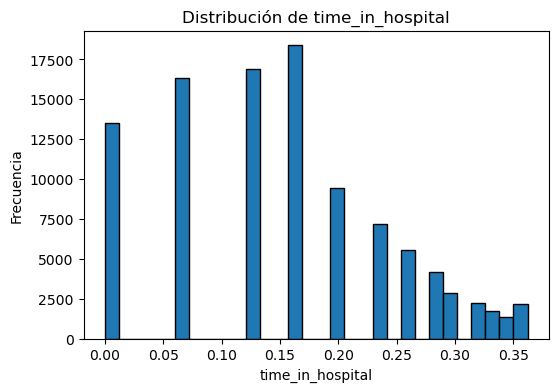

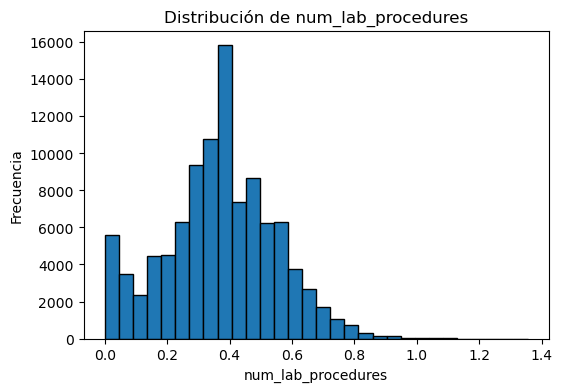

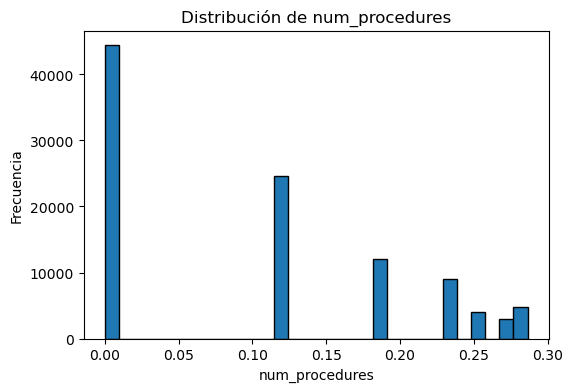

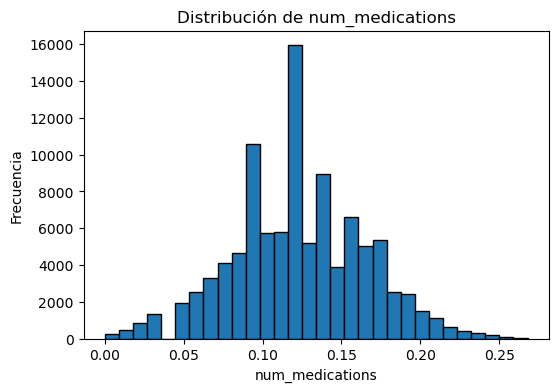

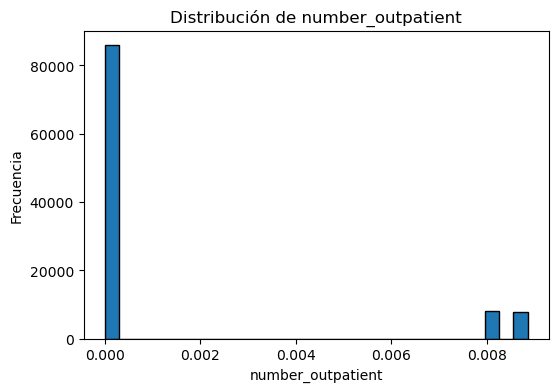

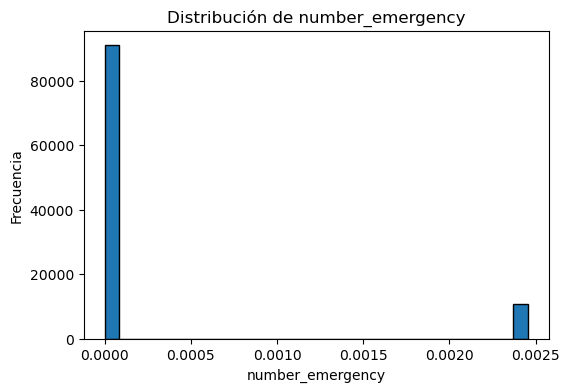

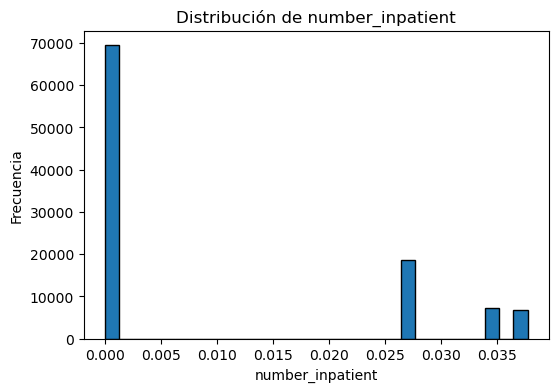

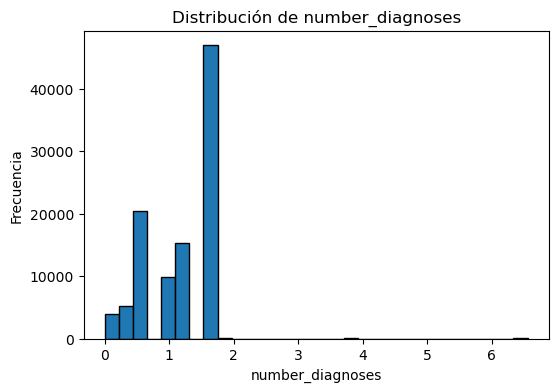

In [40]:
import matplotlib.pyplot as plt

for col in discretas:
    plt.figure(figsize=(6, 4))
    plt.hist(df_imputado[col], bins=30, edgecolor='black')
    plt.title(f'Distribución de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    plt.show()

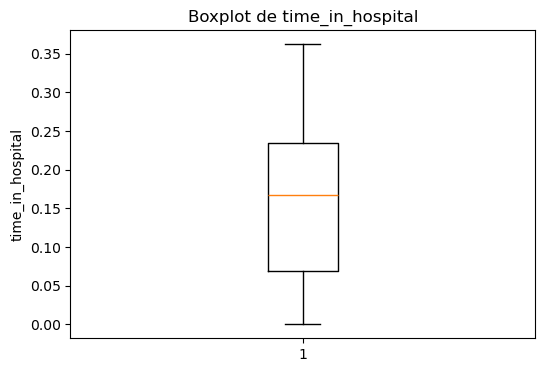

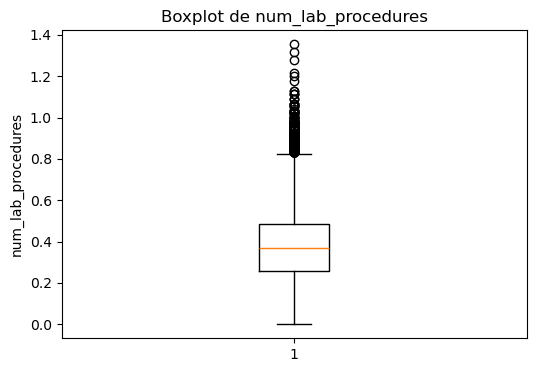

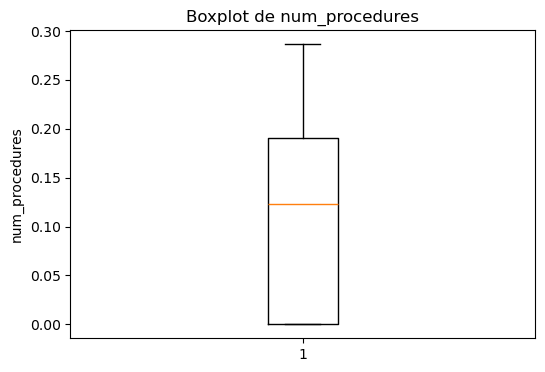

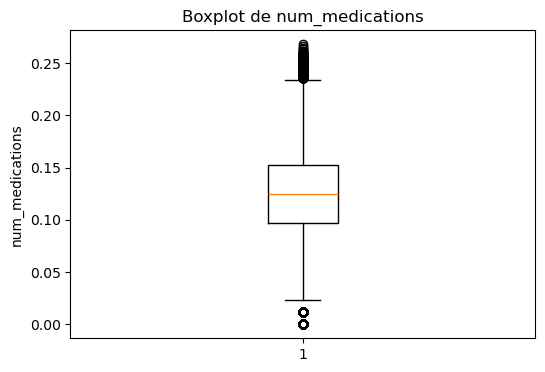

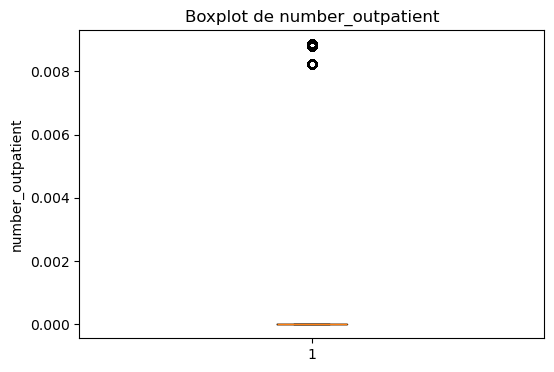

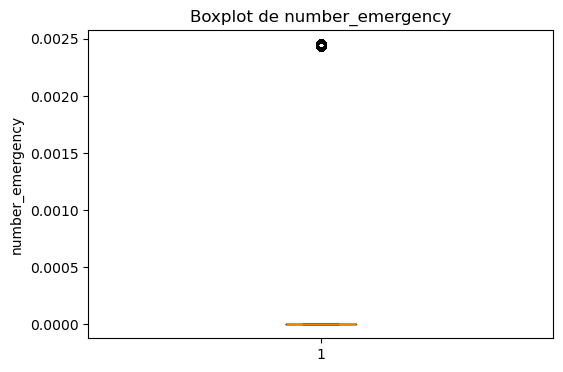

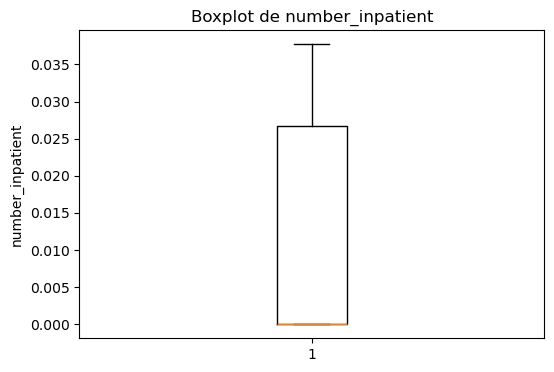

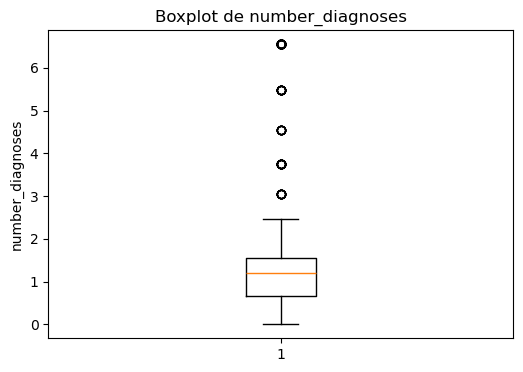

In [41]:
import matplotlib.pyplot as plt

for col in discretas:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df_imputado[col].dropna())
    plt.title(f'Boxplot de {col}')
    plt.ylabel(col)
    plt.show()

Se nota que disminuyó la asimetría de los datos, sin embargo aun esta la presencia de datos atípicos por tanto se aplica una normalización robusta

In [42]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

df_imputado[discretas] = scaler.fit_transform(df_imputado[discretas])

df_imputado.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.0,101766.0,101766.0,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,1.972171,3.581845,5.811175,-0.070328,-0.001641,-0.097469,-0.031301,0.001332,0.000260,0.363554,-0.085227
std,1.026403e+08,3.869636e+07,1.426642,5.184297,3.965923,0.587746,0.787544,0.535412,0.777955,0.003099,0.000754,0.540840,0.555414
min,1.252200e+04,1.350000e+02,1.0,1.0,1.0,-1.009876,-1.620639,-0.643058,-2.270171,0.000000,0.000000,0.000000,-1.341085
25%,8.496119e+07,2.341322e+07,1.0,1.0,1.0,-0.597265,-0.486942,-0.643058,-0.496212,0.000000,0.000000,0.000000,-0.601945
50%,1.523890e+08,4.550514e+07,1.0,1.0,7.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2.302709e+08,8.754595e+07,3.0,3.0,7.0,0.402735,0.513058,0.356942,0.503788,0.000000,0.000000,1.000000,0.398055
max,4.438672e+08,1.895026e+08,8.0,28.0,25.0,1.169500,4.344297,0.857549,2.619430,0.008855,0.002453,1.411040,6.050928


## Etapa 5. Selección y transformación de características: 

### 5.1 Selección por varianza

Calcular varianza en las variables numéricas pertinentes e identificar constantes o casi constantes. La varianza depende de las unidades: una columna en metros y la misma columna en milímetros tienen varianzas muy distintas. Un indicador poco frecuente puede ser predictivo aunque su varianza sea baja

### 5.2 Selección por correlación

Mostrar una matriz o mapa de calor para las características relevantes. Elegir Pearson para asociación lineal o Spearman para asociación monótona por rangos, y justificarlo. Si filtran pares altamente correlacionados, declarar un umbral (por ejemplo, 0.85) y una regla reproducible para decidir cuál conservar. Reportar las columnas retiradas y explicar el criterio.

La correlación mide asociación, no causalidad ni independencia. Correlación baja no descarta dependencia no lineal, un umbral por pares tampoco encuentra redundancia multivariable. 

### 5.3 WOE e Information Value

Usar WOE/IV solo si existe una variable objetivo **binaria** y la pregunta justifica una codificación supervisada. Definir explícitamente evento=1 y no evento=0. Para cada predictor mostrar la tabla de grupos, conteos por clase, distribuciones, WOE por grupo e IV total.

Para variables continuas, justificar bins y revisar tamaños, faltantes y conteos cero. Para variables categóricas, decidir qué categorías se agrupan y por qué. 


### 5.4 Análisis discriminante lineal (LDA)

LDA es supervisado: usa las etiquetas para buscar combinaciones que separen clases. Si es pertinente, documentar escalado, variables de entrada, priors y número de componentes. El máximo de ejes discriminantes es $\min(p, C-1)$, donde $p$ es el número de características y $C$ el número de clases. Con dos clases solo hay un eje discriminante.

Distinguir LDA como transformador para visualizar/reducir dimensiones de LDA como clasificador. Mostrar una proyección 1D o 2D cuando sea posible y explicar qué clases se separan. 

### 5.5 Análisis de componentes principales (PCA)

PCA es no supervisado: encuentra combinaciones que conservan varianza, sin consultar la etiqueta. Estandarizar las variables cuando sus escalas/unidades sean distintas y justificar el escalado cuando deban conservarse magnitudes originales. El ajuste y el escalador se aprenden solo en entrenamiento.

Mostrar varianza explicada individual y acumulada, justificar cuántos componentes se conservan. Interpretar los pesos principales y, si ayuda, graficar las primeras componentes. 

# Entregables obligatorios

Cada equipo entregará estos tres productos:

### 1. Presentación con diapositivas

**(15 min de presentación y 5 min de preguntas):** Debe comunicar el problema, los datos asignados, el método de procesamiento, los hallazgos más importantes, las limitaciones y las conclusiones. Incluyan figuras legibles, títulos y una explicación breve de qué evidencia aporta cada una. Todas las personas del equipo deben poder explicar el trabajo y responder preguntas.

### 2. Reporte digital del trabajo realizado

El **reporte** se entregará como documento digital elaborado en computadora; **no se aceptan fotografías de hojas o cuadernos**. Como mínimo, debe incluir:

- Nombre y apellidos de todas las personas integrantes.
- Descripción del problema, pregunta, objetivo y solución propuesta.
- Fuente, liga del dataset, descripción de datos y diccionario de variables.
- **Proceso realizado (Etapa 1-5)**: extracción, limpieza, decisiones de transformación y métodos utilizados.
- Resultados con figuras/tablas y su interpretación.
- **Un capítulo que describa la solución que se propuso para el problema.**
- **El código generado por el equipo para realizar el proyecto.** Puede organizarse en bloques legibles en el reporte y complementarse con el notebook entregado por separado, debe quedar claro qué código produjo los resultados.
- **Una sección de conclusiones.**
- Limitaciones, referencias y explicación de las decisiones relevantes.

**Impresión:** no es necesario imprimir a color. Diseñen las figuras para que se distingan en escala de grises, usen tipos de línea, marcadores, etiquetas o patrones además del color.

**Estructura sugerida del reporte:** 
- portada e integrantes
- resumen
- contexto de los datos y fuente
- Metodología/proceso
- Capítulo de solución propuesta (Etapas 1- 5)
- Resultados y figuras
- Limitaciones
- Conclusiones, referencias
- Apéndice de código si se requiere.

### 3. Código en Jupyter notebook

El notebook debe documentar el proceso completo: código, análisis, comentarios, tablas y gráficas. Debe ejecutarse en orden y ser comprensible para alguien que no participó en su elaboración.

- Incluir nombres completos, equipo, pregunta y liga asignada.
- Mantener comentarios y texto Markdown que expliquen qué se hace y por qué.
- No omitir celdas necesarias ni depender de variables creadas manualmente en otra sesión.
- Usar rutas relativas, indicar formato y fuentes de datos y no incluir credenciales privadas.
- Mostrar las figuras y salidas que se discuten en el reporte.
- Registrar decisiones, parámetros y semilla aleatoria cuando aplique.
- Ejecutar desde un kernel limpio antes de entregar y revisar que no haya errores.
- Mantener la versión original de los datos; no guardar archivos derivados sobre el original sin indicarlo.